# Figure 2 descriptive mechanism candidate

Generates the current Figure 2 candidate from existing map, PDP, segment-combination, and overlap-summary inputs.


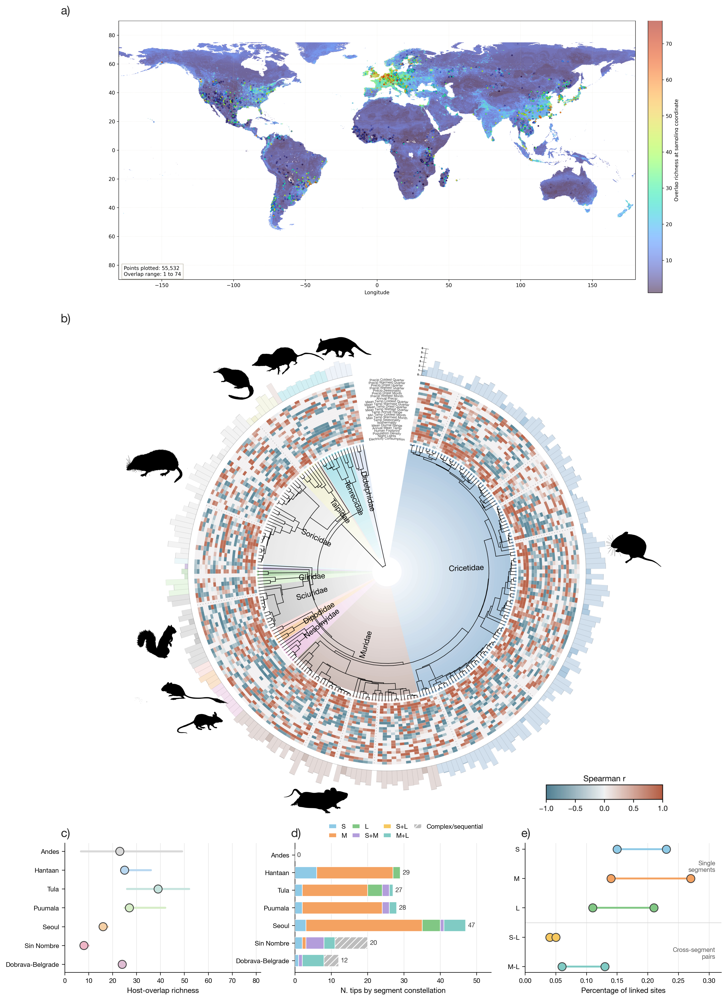

Notebooks/figures/figure2_candidate1.png
Notebooks/figures/figure2_candidate1.pdf
Notebooks/figures/figure2_candidate1.svg


In [1]:
from pathlib import Path
from PIL import Image, ImageDraw
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from IPython.display import Image as DisplayImage, display

ROOT = Path('/Users/ricardorivero/Documents/GitHub/HantaReassortment')
OUT_PNG = ROOT / 'notebooks/figures/figure2_candidate1.png'
OUT_PDF = ROOT / 'notebooks/figures/figure2_candidate1.pdf'
OUT_SVG = ROOT / 'notebooks/figures/figure2_candidate1.svg'

mpl.rcParams.update({
    'font.family': ['Helvetica Neue', 'Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 9,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 7.8,
    'axes.linewidth': 0.7,
    'xtick.major.width': 0.7,
    'ytick.major.width': 0.7,
    'savefig.facecolor': 'white',
})

species_order = [
    'orthohantavirus_andesense',
    'orthohantavirus_hantanense',
    'orthohantavirus_tulaense',
    'orthohantavirus_puumalaense',
    'orthohantavirus_seoulense',
    'orthohantavirus_sinnombreense',
    'orthohantavirus_dobravaense',
]

labels = {
    'orthohantavirus_andesense': 'Andes',
    'orthohantavirus_dobravaense': 'Dobrava-Belgrade',
    'orthohantavirus_hantanense': 'Hantaan',
    'orthohantavirus_puumalaense': 'Puumala',
    'orthohantavirus_seoulense': 'Seoul',
    'orthohantavirus_sinnombreense': 'Sin Nombre',
    'orthohantavirus_tulaense': 'Tula',
}

species_colors = {
    'orthohantavirus_andesense': '#d9d9d9',
    'orthohantavirus_hantanense': '#b8d7f0',
    'orthohantavirus_tulaense': '#c6e4de',
    'orthohantavirus_puumalaense': '#d6edc7',
    'orthohantavirus_seoulense': '#f5d0a6',
    'orthohantavirus_sinnombreense': '#efb5c6',
    'orthohantavirus_dobravaense': '#dfbdd3',
}

combo_order = ['S', 'M', 'L', 'S+M', 'S+L', 'M+L', 'Sequential/Complex']
combo_colors = {
    'S': '#8ecae6',
    'M': '#f4a261',
    'L': '#81c784',
    'S+M': '#b39ddb',
    'S+L': '#f6c85f',
    'M+L': '#80cbc4',
    'Sequential/Complex': '#bdbdbd',
}
combo_hatches = {key: '' for key in combo_order}
combo_hatches['Sequential/Complex'] = '///'

ld_items = pd.DataFrame({
    'item': ['S', 'M', 'L', 'S-M', 'S-L', 'M-L'],
    'lo': [0.15, 0.14, 0.11, 0.02, 0.04, 0.06],
    'hi': [0.23, 0.27, 0.21, 0.02, 0.05, 0.13],
    'color': ['#8ecae6', '#f4a261', '#81c784', '#b39ddb', '#f6c85f', '#80cbc4'],
})

# Panel A: reuse the existing ArHa/SDM overlap map, remove old title/callout, and set the background to white.
map_img = Image.open(ROOT / 'results/figures/candidate_paper_figures/arha_host_overlap_map.png').convert('RGBA')
arr = np.array(map_img)
r, g, b, a = [arr[..., i] for i in range(4)]
background_mask = (r > 232) & (g > 228) & (b > 218)
arr[background_mask, 0:3] = 255
map_img = Image.fromarray(arr).convert('RGB')
draw = ImageDraw.Draw(map_img)
#draw.rectangle((120, 1990, 1045, 2305), fill=(255, 255, 255))
map_crop = map_img.crop((120, 155, 4820, 2446))

# Panel B: use the final manually corrected host SDM/PDP phylogeny panel.
pdp_img = Image.open(ROOT / 'notebooks/figures/FInalFigures/PDP_Phylo.jpg').convert('RGB')
pdp_crop = pdp_img.crop((60, 80, 4860, 4290))

# Panel C: summarize host-overlap richness at sampled locations.
direct = pd.read_csv(ROOT / 'model_test/reports/direct516_reassortant_segment_combinations.tsv', sep='\t')
audit = pd.read_csv(ROOT / 'model_test/reports/sequence_geo_location_overlap_audit_manual_plus_tula.tsv', sep='\t')
joined = direct.merge(
    audit[['tip_name', 'geoquery_overlap', 'used_for_main_overlap']],
    left_on='sequence_id',
    right_on='tip_name',
    how='left',
)
joined = joined[joined['used_for_main_overlap'].fillna(True)]
overlap_stats = (
    joined.groupby('species')['geoquery_overlap']
    .agg(
        median='median',
        q25=lambda s: np.nanpercentile(s.dropna(), 25) if s.notna().any() else np.nan,
        q75=lambda s: np.nanpercentile(s.dropna(), 75) if s.notna().any() else np.nan,
    )
    .reset_index()
    .set_index('species')
    .reindex(species_order)
    .reset_index()
)

# Panel D: reassortant segment constellations.
# S+M+L is not shown as a single three-segment exchange class. For a
# three-segment genome, those labels indicate complex, sequential, or
# unresolved ancestry across the root-to-tip history.
positive = direct[direct['segment_pattern'] != 'none'].copy()
positive['display_pattern'] = positive['segment_pattern'].replace({'S+M+L': 'Sequential/Complex'})
combo_counts = (
    positive.groupby(['species', 'display_pattern'])
    .size()
    .unstack(fill_value=0)
    .reindex(index=species_order, columns=combo_order, fill_value=0)
)

fig = plt.figure(figsize=(11.75, 17.25), dpi=240)
gs = GridSpec(
    3,
    6,
    figure=fig,
    height_ratios=[2.15, 3.75, 1.0],
    width_ratios=[1, 1, 1, 1, 1, 1],
    left=0.04,
    right=0.995,
    top=0.99,
    bottom=0.048,
    wspace=0.42,
    hspace=0.10,
)

# a)
axA = fig.add_subplot(gs[0, :])
axA.imshow(map_crop)
axA.set_axis_off()
axA.set_anchor('N')

# b)
axB = fig.add_subplot(gs[1, :])
axB.imshow(pdp_crop)
axB.set_axis_off()
axB.set_anchor('C')

# c)
axC = fig.add_subplot(gs[2, 0:2])
y = np.arange(len(overlap_stats))
x = overlap_stats['median'].astype(float).values
lo = overlap_stats['q25'].astype(float).values
hi = overlap_stats['q75'].astype(float).values
for i, (m, l, h) in enumerate(zip(x, lo, hi)):
    if np.isfinite(m):
        line_color = species_colors[overlap_stats.loc[i, 'species']]
        axC.plot([l, h], [i, i], color=line_color, lw=2.5, solid_capstyle='round', zorder=1)
        axC.plot([m, m], [i - 0.12, i + 0.12], color=line_color, lw=0.9, zorder=2)
axC.scatter(
    x,
    y,
    s=100,
    c=[species_colors[s] for s in overlap_stats['species']],
    edgecolor='#404040',
    linewidth=1,
    zorder=3,
)
axC.set_yticks(y, [labels[s] for s in overlap_stats['species']])
axC.invert_yaxis()
axC.set_xlim(0, 82)
axC.set_xlabel('Host-overlap richness')
axC.grid(axis='x', color='#e9e9e9', lw=0.7, zorder=0)
axC.set_axisbelow(True)
axC.spines[['top', 'right']].set_visible(False)

# d)
axD = fig.add_subplot(gs[2, 2:4])
y = np.arange(len(combo_counts))
left = np.zeros(len(combo_counts))
axD.set_axisbelow(True)
axD.grid(axis='x', color='#e9e9e9', lw=0.7, zorder=0)
for pat in combo_order:
    vals = combo_counts[pat].values
    axD.barh(
        y,
        vals,
        left=left,
        height=0.68,
        color=combo_colors[pat],
        edgecolor='white',
        linewidth=0.7,
        label=pat,
        hatch=combo_hatches[pat],
        zorder=3,
    )
    left += vals
for i, total in enumerate(left):
    axD.text(total + 0.6, i, f'{int(total)}', va='center', ha='left', fontsize=8, color='#333333')
axD.set_yticks(y, [labels[s] for s in combo_counts.index])
axD.invert_yaxis()
axD.set_xlim(0, max(left) + 7)
axD.set_xlabel('N. tips by segment constellation')
axD.spines[['top', 'right']].set_visible(False)
axD.legend(
    ncol=4,
    frameon=False,
    loc='lower left',
    bbox_to_anchor=(0.16, 1.015),
    borderaxespad=0,
    handlelength=1.2,
    columnspacing=0.8,
)

# e)
axE = fig.add_subplot(gs[2, 4:6])
y = np.arange(len(ld_items))
axE.set_axisbelow(True)
axE.grid(axis='x', color='#e9e9e9', lw=0.7, zorder=0)
for i, row in ld_items.iterrows():
    axE.plot([row['lo'], row['hi']], [i, i], color=row['color'], lw=2.3, solid_capstyle='round', zorder=2)
    axE.scatter([row['lo'], row['hi']], [i, i], s=100, color=row['color'], edgecolor='#404040', linewidth=1, zorder=3)
axE.axhline(2.5, color='#d9d9d9', lw=0.8, zorder=1)
axE.set_yticks(y, ld_items['item'])
axE.invert_yaxis()
axE.set_xlim(0, 0.32)
axE.set_xlabel('Percentage of linked sites')
axE.spines[['top', 'right']].set_visible(False)
axE.text(0.31, 0.6, 'Single\nsegments', ha='right', va='center', fontsize=7.6, color='#5a5a5a')
axE.text(0.31, 3.55, 'Cross-segment\npairs', ha='right', va='center', fontsize=7.6, color='#5a5a5a')

label_x = axC.get_position().x0 - 0.006
for ax, lab in [(axA, 'a)'), (axB, 'b)'), (axC, 'c)'), (axD, 'd)'), (axE, 'e)')]:
    pos = ax.get_position()
    x_lab = label_x if lab in {'a)', 'b)', 'c)'} else pos.x0 - 0.006
    fig.text(x_lab, pos.y1 + 0.004, lab, ha='left', va='bottom', fontsize=14.5, color='#222222')

fig.savefig(OUT_PNG, dpi=1200, bbox_inches='tight')
fig.savefig(OUT_PDF, bbox_inches='tight')
fig.savefig(OUT_SVG, bbox_inches='tight')
plt.show()

display(DisplayImage(filename=str(OUT_PNG)))
print(OUT_PNG)
print(OUT_PDF)
print(OUT_SVG)